In [2]:
import pandas as pd

df = pd.read_csv("../../data/data_generic.csv")

print(df.shape)
display(df.head())

(210241, 9)


,time_min,cA,cB,cC,cP,cE,cG,QB,Tr
0,0.0,0.889877,1.838448,0.079503,2.370886,2.370888,0.000002,224.000000,380.000000
1,10.0,0.889572,1.839348,0.079477,2.370705,2.370707,0.000002,224.103034,380.000000
2,20.0,0.888979,1.840870,0.079425,2.370429,2.370432,0.000002,224.206062,380.000001
3,30.0,0.888328,1.842515,0.079369,2.370136,2.370138,0.000002,224.309078,380.000001
4,40.0,0.887666,1.844185,0.079311,2.369838,2.369841,0.000002,224.412075,380.000002


In [3]:

# Print the names of all columns in the dataset
# This helps us identify the time, concentrations, and operating variables
print("Column names:")
print(df.columns.tolist())


# Check how many missing values there are in each column
# Missing values may affect the evaluation of the model
print("\nMissing values:")
print(df.isnull().sum())


# Print the first time value in the dataset
# This tells us when the recorded simulation starts
print("\nFirst time value:")
print(df["time_min"].iloc[0])


# Print the last time value in the dataset
# This tells us when the recorded simulation ends
print("\nLast time value:")
print(df["time_min"].iloc[-1])


Column names:
['time_min', 'cA', 'cB', 'cC', 'cP', 'cE', 'cG', 'QB', 'Tr']

Missing values:
time_min    0
cA          0
cB          0
cC          0
cP          0
cE          0
cG          0
QB          0
Tr          0
dtype: int64

First time value:
0.0

Last time value:
2102400.0


In [4]:

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Define the chemical concentrations we want to predict
targets = ["cA", "cB", "cC", "cP", "cE", "cG"]

# Use the current concentrations to predict the next time step
# The last row has no following row, so it is excluded
X = df[targets].iloc[:-1].reset_index(drop=True)
y = df[targets].iloc[1:].reset_index(drop=True)

# Split the data in chronological order:
# first 80% for training period, last 20% for testing
split = int(0.8 * len(X))

# Select the test period
y_test = y.iloc[split:]

# Baseline prediction: the next concentration equals the current one
predictions = X.iloc[split:].to_numpy()

# Calculate evaluation metrics for each concentration
results = []

for i, target in enumerate(targets):
    # Get the actual and predicted concentrations
    actual = y_test[target].to_numpy()
    predicted = predictions[:, i]

    # Calculate Mean Absolute Error (MAE)
    mae = mean_absolute_error(actual, predicted)

    # Calculate Root Mean Squared Error (RMSE)
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    # Store the results
    results.append({
        "Concentration": target,
        "MAE": mae,
        "RMSE": rmse
    })

# Display the baseline evaluation results
results_df = pd.DataFrame(results)
display(results_df)


,Concentration,MAE,RMSE
0,cA,3.527256e-04,4.028331e-04
1,cB,7.931280e-04,8.943623e-04
2,cC,2.468987e-05,2.840083e-05
3,cP,1.313944e-04,1.548509e-04
4,cE,1.314020e-04,1.548587e-04
5,cG,7.825227e-09,1.047284e-08


In [5]:

# Check the time increments between consecutive rows
# This helps us understand the temporal structure of the dataset

time_diff = df["time_min"].diff()

print("First time increments:")
print(time_diff.iloc[1:11].tolist())

print("\nMost common time increments:")
print(time_diff.value_counts().head(10))

print("\nNumber of unique time increments:")
print(time_diff.nunique())



First time increments:
[10.0, 10.0, 10.0, 10.0, 10.0, 10.0, 10.0, 10.0, 10.0, 10.0]

Most common time increments:
time_min
10.0    210240
Name: count, dtype: int64

Number of unique time increments:
1


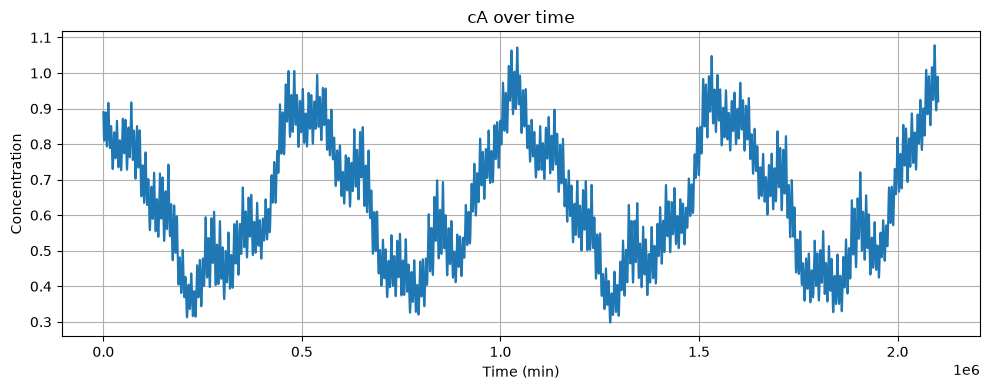

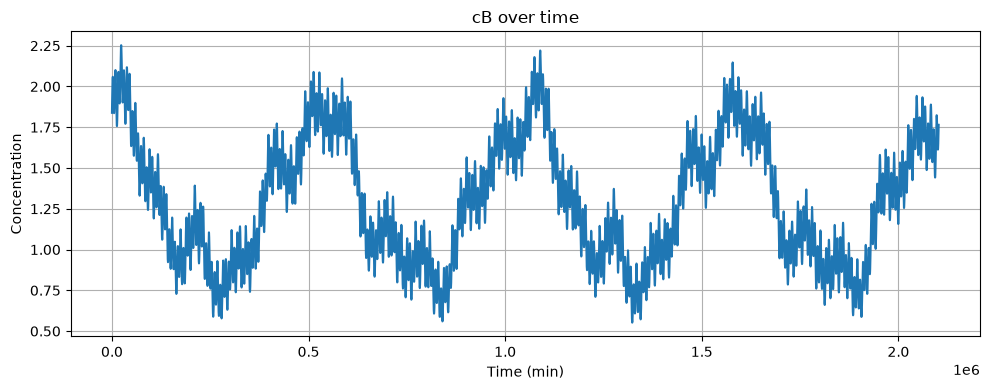

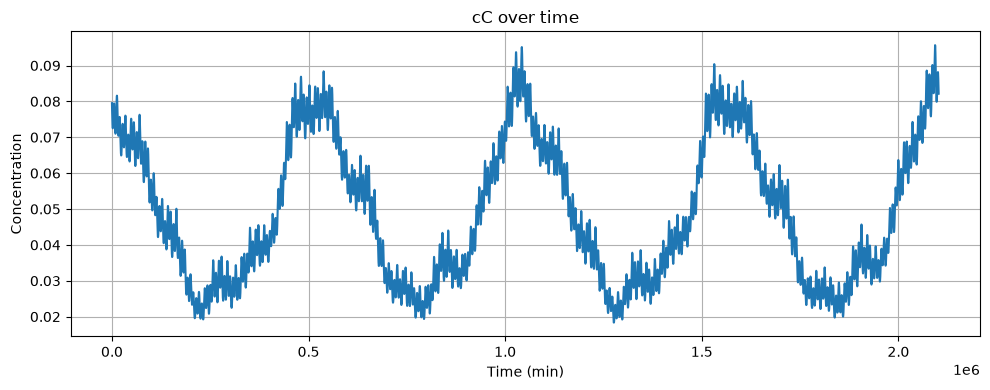

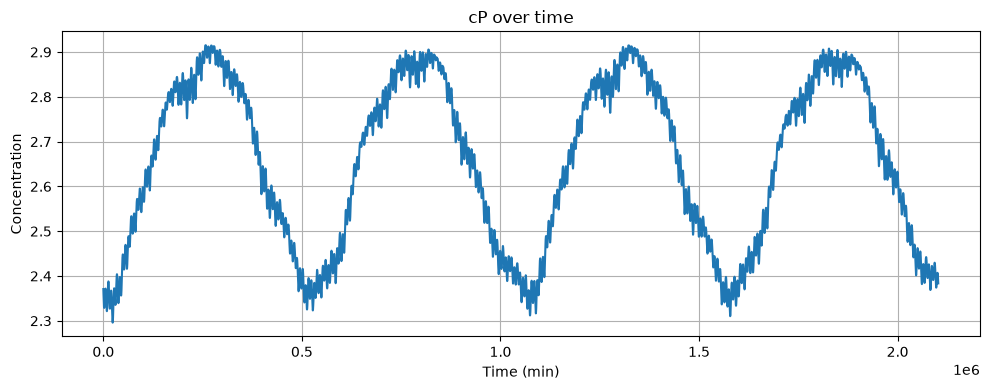

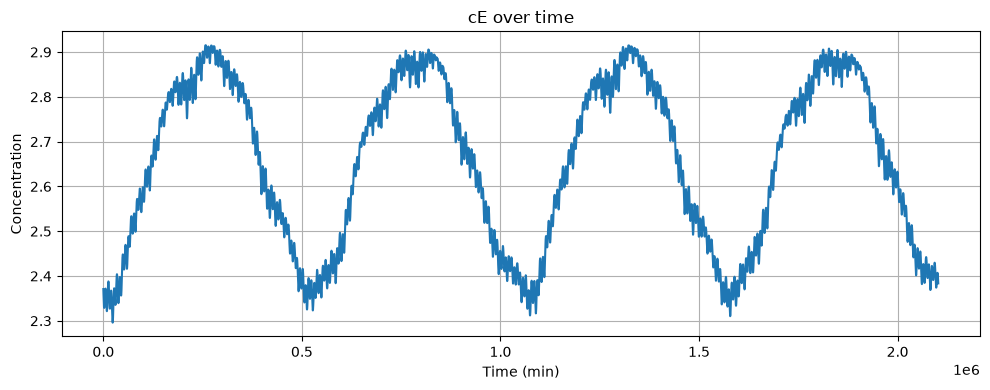

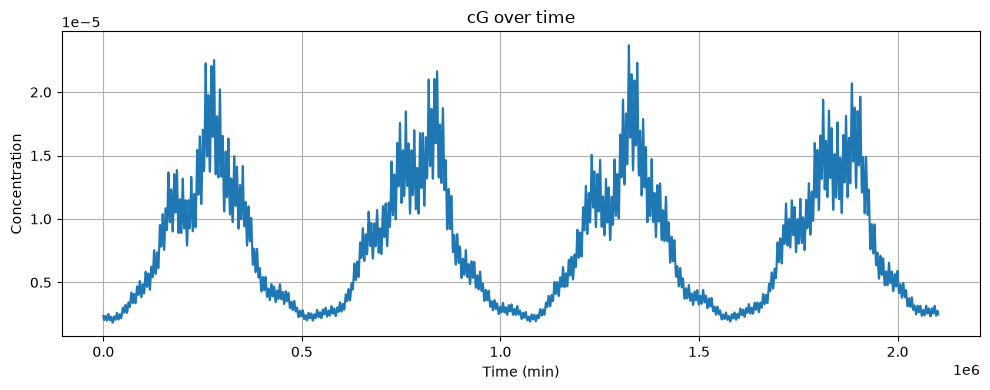

In [6]:

import matplotlib.pyplot as plt

# Define the chemical concentrations to visualize
concentrations = ["cA", "cB", "cC", "cP", "cE", "cG"]

# Create one plot for each concentration
# The x-axis represents time and the y-axis represents concentration
for column in concentrations:
    plt.figure(figsize=(10, 4))

    # Plot the concentration over time
    plt.plot(df["time_min"], df[column])

    # Add the title and axis labels
    plt.title(f"{column} over time")
    plt.xlabel("Time (min)")
    plt.ylabel("Concentration")

    # Add a grid to make the plot easier to read
    plt.grid(True)

    # Adjust the layout and display the plot
    plt.tight_layout()
    plt.show()

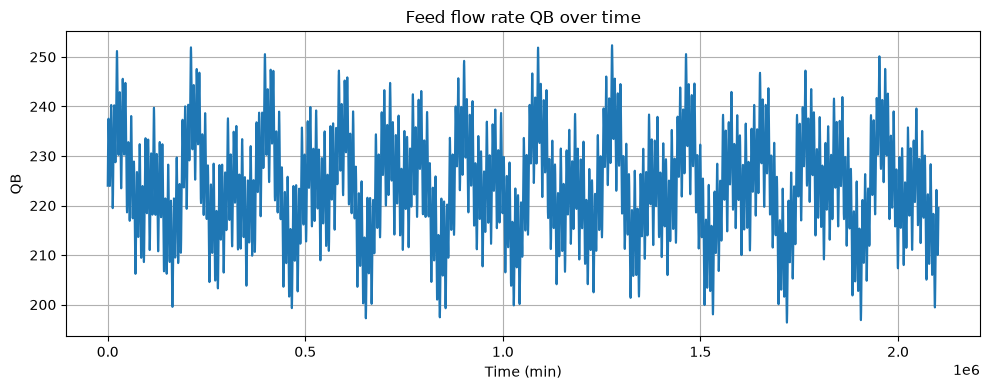

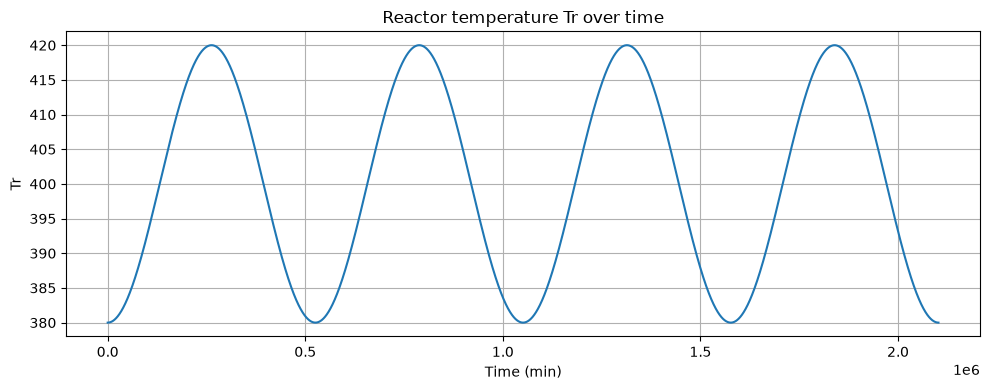

In [7]:

# Plot the operating variables over time

# Plot the feed flow rate QB
plt.figure(figsize=(10, 4))
plt.plot(df["time_min"], df["QB"])
plt.title("Feed flow rate QB over time")
plt.xlabel("Time (min)")
plt.ylabel("QB")
plt.grid(True)
plt.tight_layout()
plt.show()

# Plot the reactor temperature Tr
plt.figure(figsize=(10, 4))
plt.plot(df["time_min"], df["Tr"])
plt.title("Reactor temperature Tr over time")
plt.xlabel("Time (min)")
plt.ylabel("Tr")
plt.grid(True)
plt.tight_layout()
plt.show()


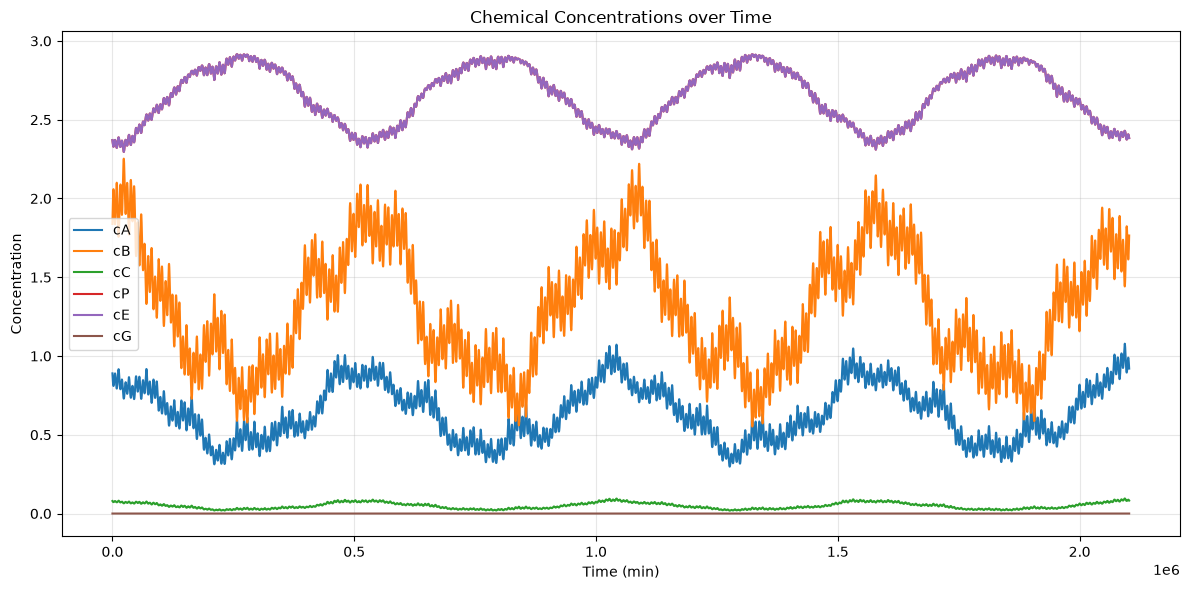

In [8]:

import matplotlib.pyplot as plt

# Define the chemical concentrations to plot
concentrations = ["cA", "cB", "cC", "cP", "cE", "cG"]

# Create one figure for all concentrations
plt.figure(figsize=(12, 6))

# Plot each concentration against time
for column in concentrations:
    plt.plot(df["time_min"], df[column], label=column)

# Add the title, axis labels, and legend
plt.title("Chemical Concentrations over Time")
plt.xlabel("Time (min)")
plt.ylabel("Concentration")
plt.legend()

# Improve readability
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Display the plot
plt.show()


In [9]:
import pandas as pd

# Load NARX results provided by Dora
y_test = pd.read_csv("../../data/y_test_results.csv")
y_pred = pd.read_csv("../../data/y_pred_results.csv")

species = ["cA", "cB", "cC", "cP", "cE", "cG"]

# Check dimensions and column names
assert len(y_test) == len(y_pred)
assert all(col in y_test.columns for col in species)
assert all(col in y_pred.columns for col in species)

# Combine actual and predicted values
actual = y_test[species].reset_index(drop=True).add_suffix("_actual")
predicted = y_pred[species].reset_index(drop=True).add_suffix("_predicted")

ml_data = pd.concat([actual, predicted], axis=1)

display(ml_data.head())
print("Number of test observations:", len(ml_data))

,cA_actual,cB_actual,cC_actual,cP_actual,cE_actual,cG_actual,cA_predicted,cB_predicted,cC_predicted,cP_predicted,cE_predicted,cG_predicted
0,0.750616,1.254253,0.058134,2.626278,2.626284,0.000005,0.750375,1.254258,0.058111,2.626373,2.626378,0.000005
1,0.751057,1.253256,0.058166,2.626442,2.626448,0.000005,0.750794,1.253029,0.058138,2.626625,2.626630,0.000005
2,0.751494,1.252266,0.058198,2.626606,2.626611,0.000005,0.751321,1.252031,0.058178,2.626755,2.626760,0.000005
3,0.751928,1.251283,0.058230,2.626767,2.626773,0.000005,0.751709,1.251045,0.058205,2.626936,2.626941,0.000005
4,0.752359,1.250307,0.058261,2.626928,2.626934,0.000005,0.752131,1.249770,0.058232,2.627202,2.627208,0.000005


Number of test observations: 42048


In [10]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

species = ["cA", "cB", "cC", "cP", "cE", "cG"]

results = []

for name in species:

    actual = ml_data[f"{name}_actual"]
    predicted = ml_data[f"{name}_predicted"]

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    r2 = r2_score(actual, predicted)

    results.append({
        "Species": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

evaluation_results = pd.DataFrame(results)

display(evaluation_results)

,Species,MAE,RMSE,R2
0,cA,1.527730e-03,4.561244e-03,0.999327
1,cB,1.714639e-03,4.567428e-03,0.999806
2,cC,1.379279e-04,3.991554e-04,0.999550
3,cP,7.566806e-04,2.227199e-03,0.999813
4,cE,7.567019e-04,2.227265e-03,0.999813
5,cG,2.378043e-08,7.775463e-08,0.999727


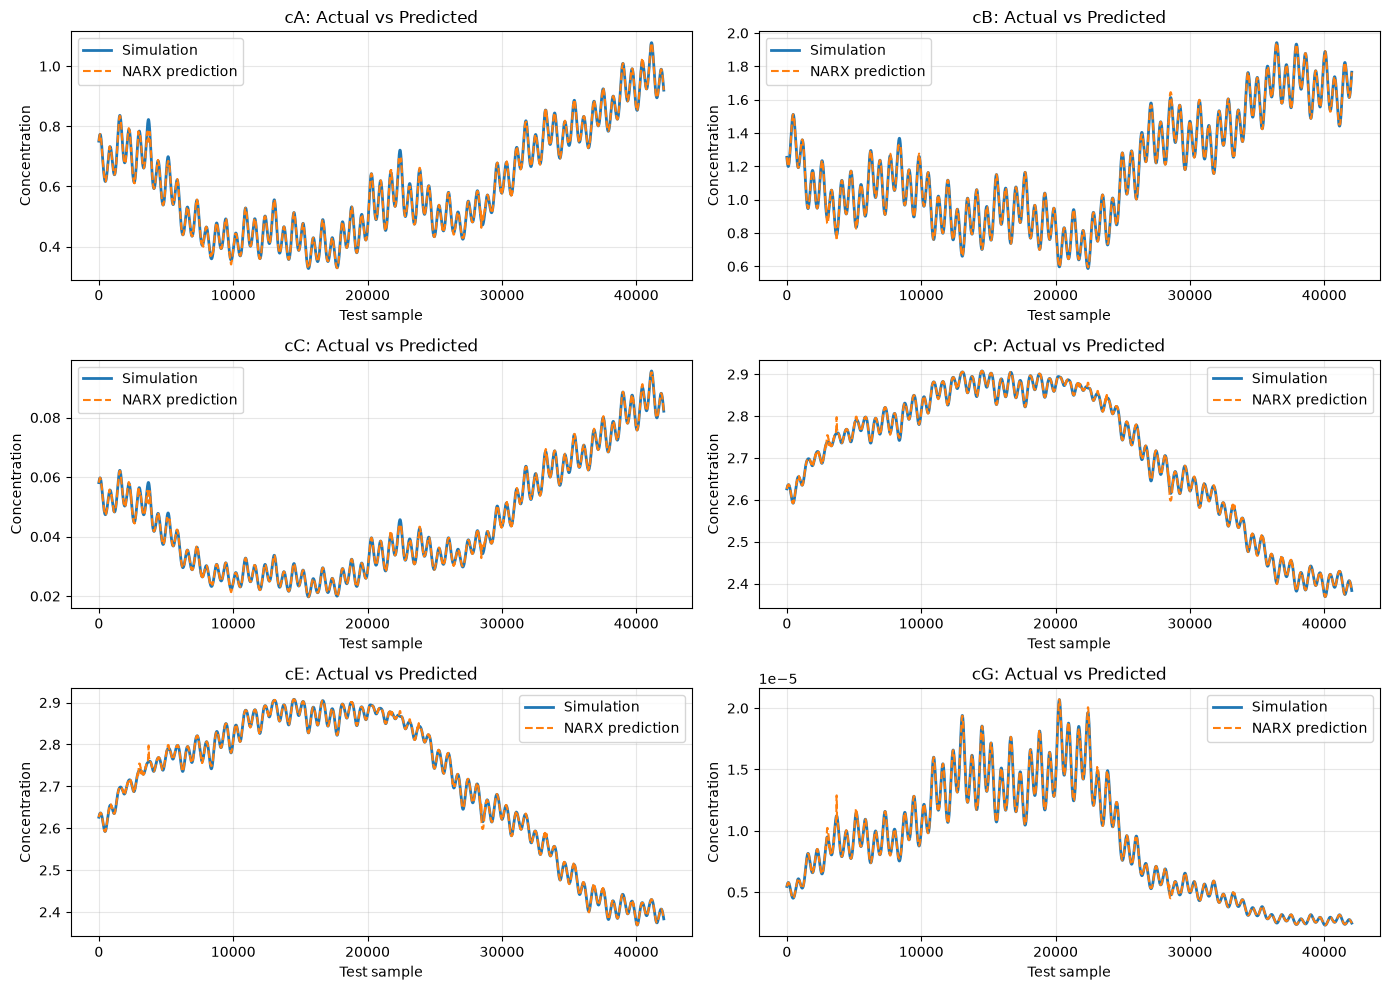

In [11]:
import matplotlib.pyplot as plt
import numpy as np

species = ["cA", "cB", "cC", "cP", "cE", "cG"]

# Show all test observations
n = len(ml_data)

fig, axes = plt.subplots(3, 2, figsize=(14, 10))

for ax, name in zip(axes.flat, species):

    actual = ml_data[f"{name}_actual"].values[:n]
    predicted = ml_data[f"{name}_predicted"].values[:n]

    ax.plot(actual, label="Simulation", linewidth=2)
    ax.plot(predicted, label="NARX prediction",
            linestyle="--", linewidth=1.5)

    ax.set_title(f"{name}: Actual vs Predicted")
    ax.set_xlabel("Test sample")
    ax.set_ylabel("Concentration")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

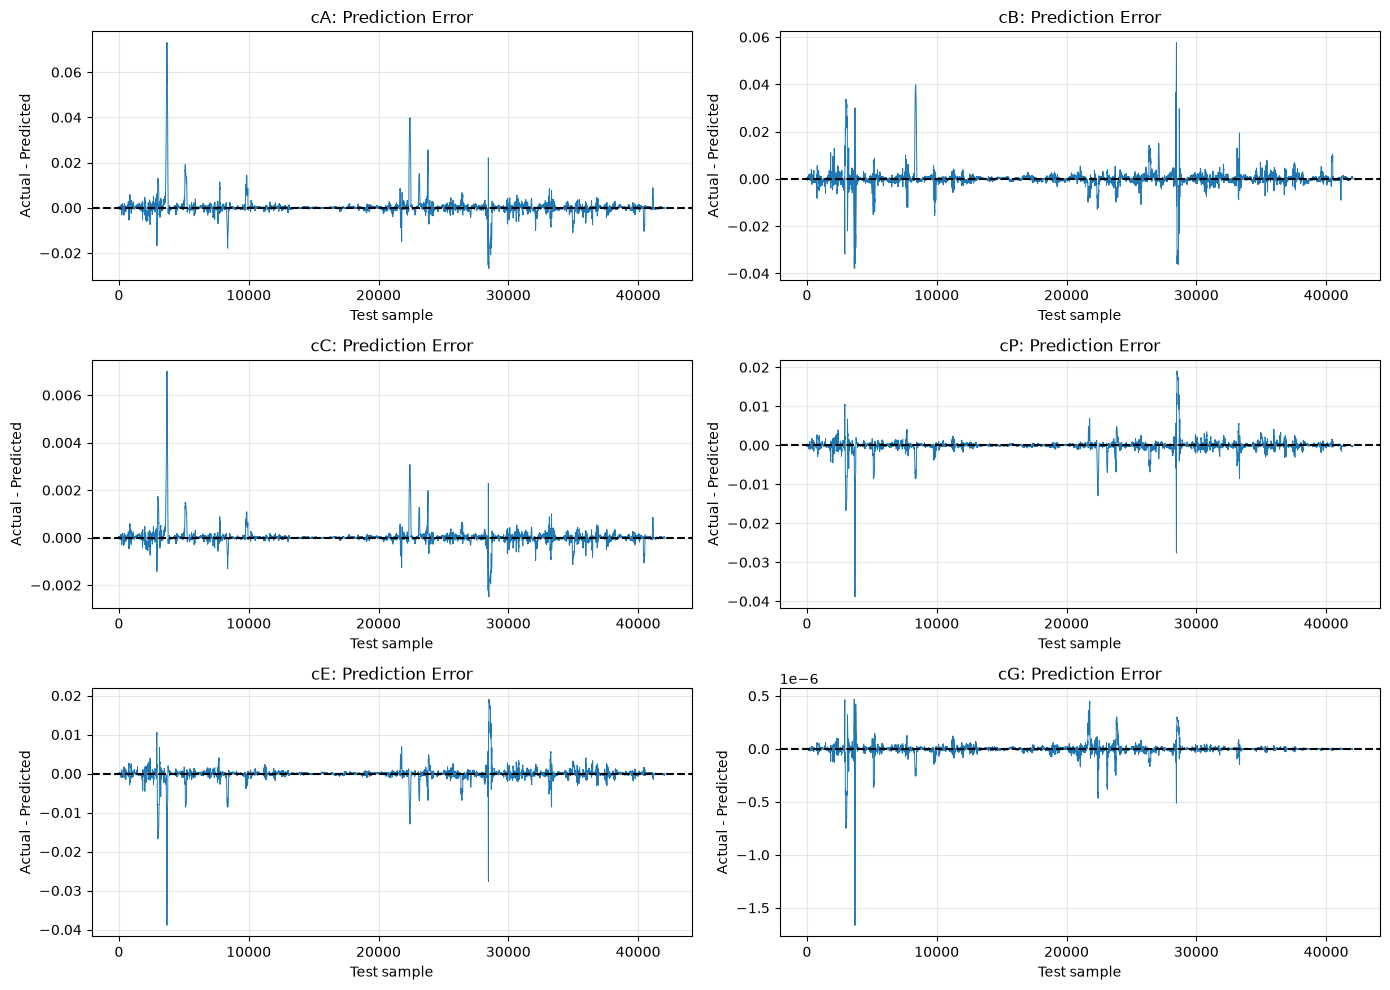

In [12]:
import matplotlib.pyplot as plt

species = ["cA", "cB", "cC", "cP", "cE", "cG"]

fig, axes = plt.subplots(3, 2, figsize=(14, 10))

for ax, name in zip(axes.flat, species):
    actual = ml_data[f"{name}_actual"]
    predicted = ml_data[f"{name}_predicted"]

    error = actual - predicted

    ax.plot(error.values, linewidth=0.7)
    ax.axhline(0, color="black", linestyle="--")

    ax.set_title(f"{name}: Prediction Error")
    ax.set_xlabel("Test sample")
    ax.set_ylabel("Actual - Predicted")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()